# Workflow Evaluation - Metrics by Category

Standalone analysis of `evaluation_results/eval_20261024_163408.csv`.

**Data:** 175 evaluation cases (5 stocks x 5 categories x 7 prompt styles) x 3 workflows (A/B/C) = 525 rows.
Each workflow ran the identical 175 cases, so workflow comparisons are **paired**.

Comparisons:
- Workflow A (`agentic_workflow_A_bert`)
- Workflow B (`agentic_workflow_B_finbert`)
- Workflow C (`agentic_workflow_C_no_sentiment`)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT = Path().resolve().parent
# analysis always reads the latest exported eval CSV (timestamped filenames sort chronologically)
CSV_PATH = sorted((PROJECT / "evaluation_results").glob("eval_*.csv"))[-1]

WORKFLOWS = ["A", "B", "C"]
CATEGORIES = ["earnings", "analyst_ratings", "product_innovation",
              "market_trends", "risks_controversies"]
STOCKS = ["AAPL", "AMZN", "MSFT", "NVDA", "TSLA"]

METRICS = ["TaskCompletionMetric", "ArgumentCorrectnessMetric",
           "AnswerRelevancyMetric", "HallucinationMetric"]
METRIC_LABELS = ["Task Completion", "Argument Correctness",
                 "Answer Relevancy", "Hallucination"]

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

print(f"CSV: {CSV_PATH}")

CSV: /run/media/horizontal_roterien_katze/U/project_finnessly/evaluation_results/eval_20261028_195355.csv


## 1. Load & validate

> **Data note:** the row-level `success` column in the CSV means "all four evaluators returned a score" rather than overall quality. On 2026-10-28 the 10 cases that had incomplete evaluations (21 missing metric scores, mostly judge 503/timeouts on workflow-B risks_controversies cases with 120+ recorded tool calls) were re-evaluated from the cached runs; all 525 rows now have complete scores, so no cells are excluded. Per-metric `*_passed` (threshold 0.5) is the quality flag used alongside raw scores.


In [2]:
df = pd.read_csv(CSV_PATH)

# derive boolean pass columns from *_passed
metric_pass_cols = {m: pd.Series(df[f"{m}_passed"]).astype(bool) for m in METRICS}

for m in METRICS:
    df[f"{m}_passed_bool"] = metric_pass_cols[m]

print(df.shape)
assert set(df["workflow"].unique()) == set(WORKFLOWS)
assert set(df["category"].unique()) == set(CATEGORIES), df["category"].unique()

# every (prompt_id) must appear exactly once per workflow
counts = df.groupby("prompt_id")["workflow"].nunique()
assert (counts == 3).all(), "some cases are missing a workflow run"
assert df.duplicated(["prompt_id", "workflow"]).sum() == 0

n_cases = df["prompt_id"].nunique()
print(f"{n_cases} cases x {len(WORKFLOWS)} workflows = {len(df)} rows")
print()
print(df.groupby("workflow").size())

(525, 23)
175 cases x 3 workflows = 525 rows

workflow
A    175
B    175
C    175
dtype: int64


## 2. Headline: overall workflow comparison

Overall mean score per metric and overall success rate, per workflow.
Since runs are paired, deltas are computed per case and averaged.

In [3]:
overall = df.groupby("workflow")[[f"{m}_score" for m in METRICS]].mean()
overall = overall.rename(columns={f"{m}_score": lbl for m, lbl in zip(METRICS, METRIC_LABELS)})
overall = overall.reindex(WORKFLOWS)

overall["Success rate"] = df.groupby("workflow")["success"].mean().reindex(WORKFLOWS) * 100

display(overall.round(3))

,Task Completion,Argument Correctness,Answer Relevancy,Hallucination,Success rate
workflow,,,,,
A,0.418,0.129,0.765,0.548,100.0
B,0.429,0.161,0.789,0.585,100.0
C,0.412,0.072,0.838,0.487,100.0


### Overall distribution per metric (your main chart)

One boxplot subplot per metric; x-axis = workflow.

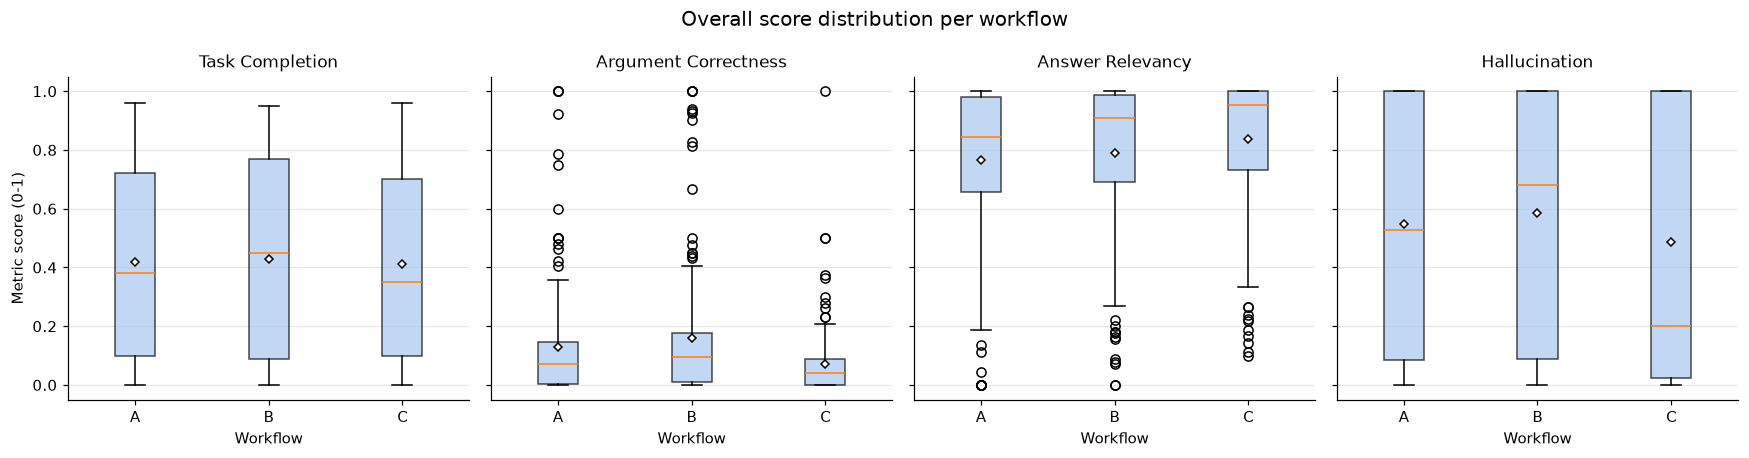

In [4]:
fig, axes = plt.subplots(1, len(METRICS), figsize=(4 * len(METRICS), 4.2), sharey=True)

for ax, metric, label in zip(axes, METRICS, METRIC_LABELS):
    data = [df.loc[df["workflow"] == w, f"{metric}_score"] for w in WORKFLOWS]
    bp = ax.boxplot(data, tick_labels=WORKFLOWS, showmeans=True, patch_artist=True,
                    meanprops={"marker": "D", "markerfacecolor": "white",
                               "markeredgecolor": "black", "markersize": 4})
    for box in bp["boxes"]:
        box.set(facecolor="#a9c7f0", alpha=0.7)
    ax.set_title(label, fontsize=11)
    ax.set_xlabel("Workflow")
    ax.grid(axis="y", alpha=0.3)

axes[0].set_ylabel("Metric score (0-1)")
fig.suptitle("Overall score distribution per workflow", fontsize=13)
fig.tight_layout()
fig.savefig(PROJECT / "reports" / "eval_boxplots_overall.png", bbox_inches="tight")
plt.show()

## 3. Per-category analysis (main)

Each of the following cells breaks the four metrics down by the 5 categories,
comparing workflows side by side within each category.

In [5]:
def cat_table(metric):
    tbl = (df.pivot_table(index="category", columns="workflow",
                          values=f"{metric}_score", aggfunc="mean")
             .reindex(index=CATEGORIES, columns=WORKFLOWS))
    tbl["best"] = tbl.idxmax(axis=1)
    return tbl.round(3)


for metric, label in zip(METRICS, METRIC_LABELS):
    print(f"--- {label}: mean score by category x workflow ---")
    display(cat_table(metric))
    print()

--- Task Completion: mean score by category x workflow ---


workflow,A,B,C,best
category,,,,
earnings,0.288,0.346,0.352,C
analyst_ratings,0.256,0.196,0.180,A
product_innovation,0.480,0.457,0.489,C
market_trends,0.560,0.637,0.553,B
risks_controversies,0.507,0.506,0.485,A



--- Argument Correctness: mean score by category x workflow ---


workflow,A,B,C,best
category,,,,
earnings,0.169,0.189,0.079,B
analyst_ratings,0.057,0.072,0.045,B
product_innovation,0.155,0.267,0.087,B
market_trends,0.132,0.161,0.095,B
risks_controversies,0.131,0.114,0.053,A



--- Answer Relevancy: mean score by category x workflow ---


workflow,A,B,C,best
category,,,,
earnings,0.732,0.801,0.773,B
analyst_ratings,0.750,0.677,0.784,C
product_innovation,0.703,0.772,0.887,C
market_trends,0.827,0.875,0.874,B
risks_controversies,0.814,0.817,0.869,C



--- Hallucination: mean score by category x workflow ---


workflow,A,B,C,best
category,,,,
earnings,0.535,0.465,0.514,A
analyst_ratings,0.702,0.500,0.598,A
product_innovation,0.423,0.700,0.394,B
market_trends,0.583,0.691,0.402,B
risks_controversies,0.495,0.571,0.527,B


### Boxplots: category x workflow, one subplot per metric

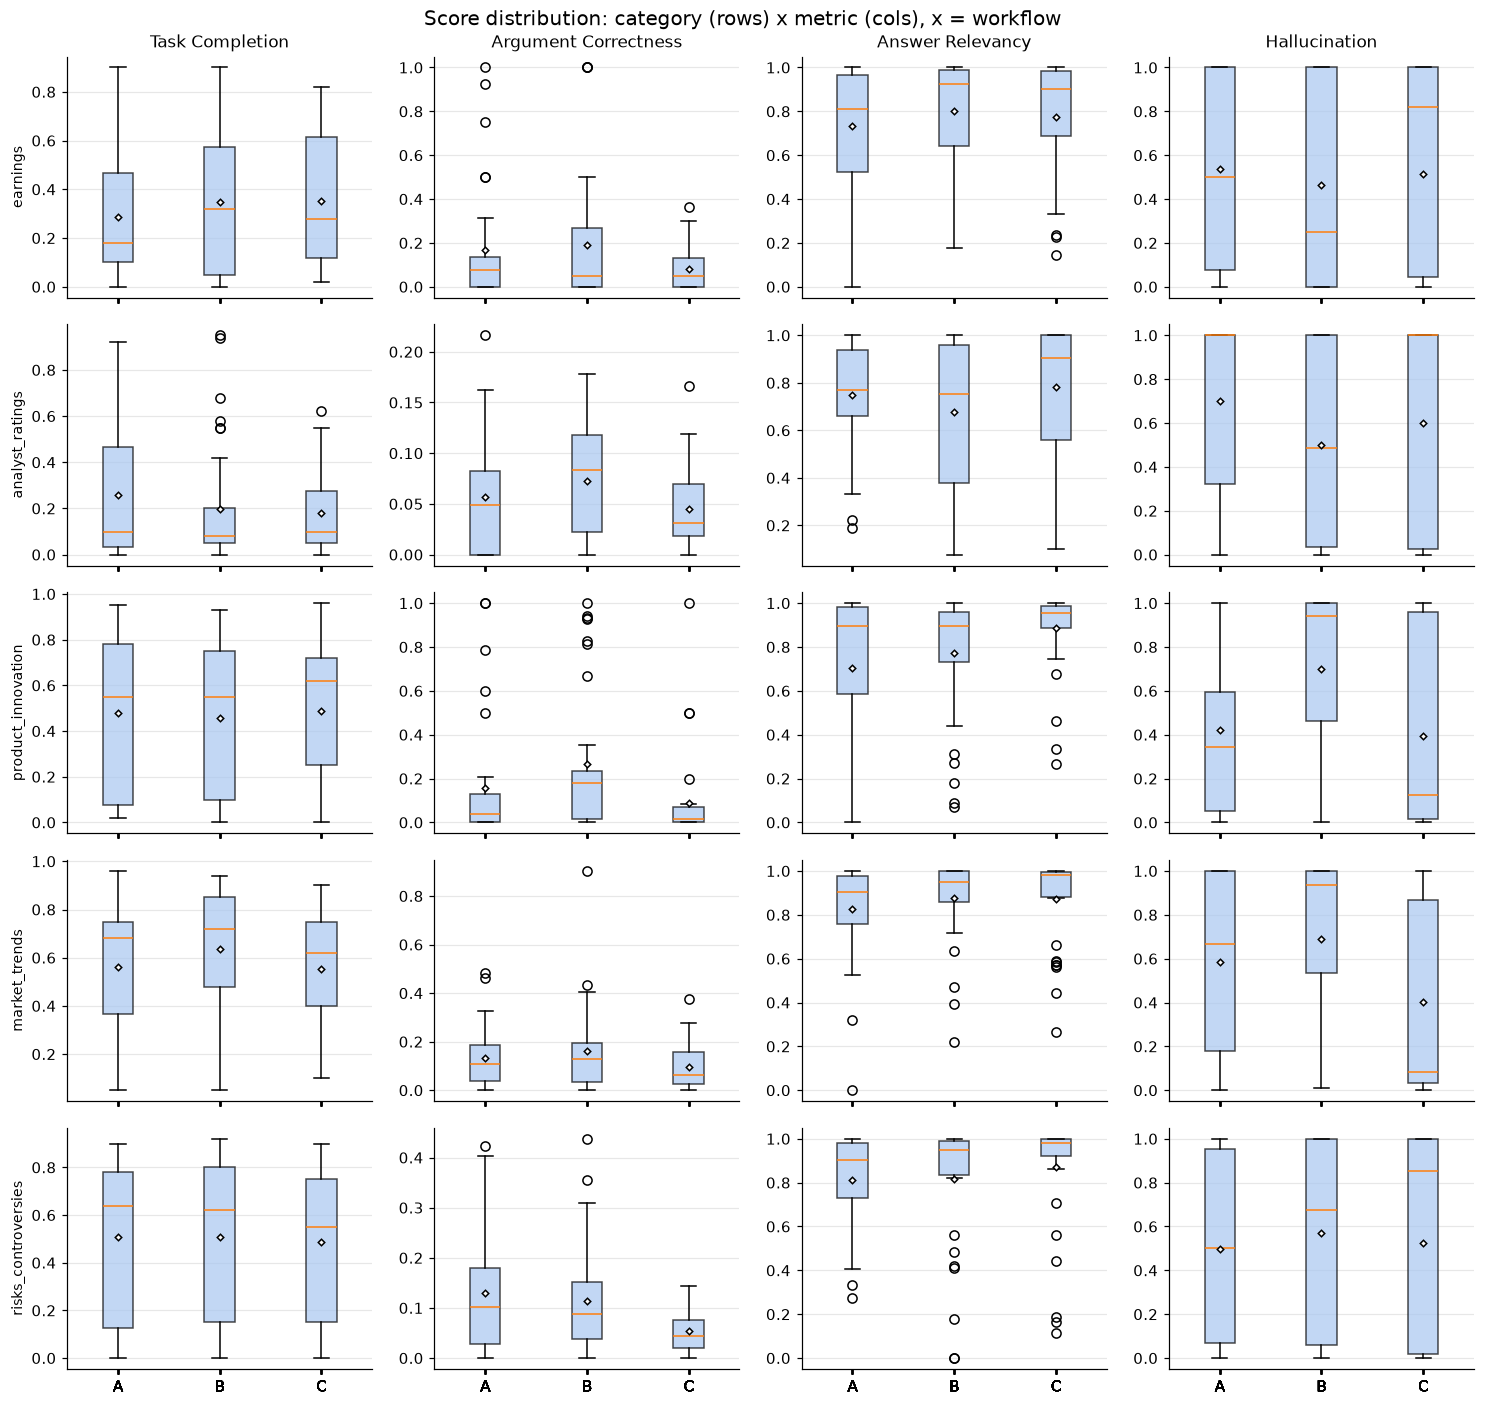

In [6]:
fig, axes = plt.subplots(len(CATEGORIES), len(METRICS),
                         figsize=(3.4 * len(METRICS), 2.6 * len(CATEGORIES)),
                         sharex=True)

for i, cat in enumerate(CATEGORIES):
    sub = df[df["category"] == cat]
    for j, (metric, label) in enumerate(zip(METRICS, METRIC_LABELS)):
        ax = axes[i, j]
        data = [sub.loc[sub["workflow"] == w, f"{metric}_score"] for w in WORKFLOWS]
        bp = ax.boxplot(data, tick_labels=WORKFLOWS,
                        showmeans=True, patch_artist=True,
                        meanprops={"marker": "D", "markerfacecolor": "white",
                                   "markeredgecolor": "black", "markersize": 3})
        for box in bp["boxes"]:
            box.set(facecolor="#a9c7f0", alpha=0.7)
        ax.grid(axis="y", alpha=0.3)
        if j == 0:
            ax.set_ylabel(cat, fontsize=9)
        if i == 0:
            ax.set_title(label, fontsize=11)

fig.suptitle("Score distribution: category (rows) x metric (cols), x = workflow",
             fontsize=13)
fig.tight_layout()
fig.savefig(PROJECT / "reports" / "eval_boxplots_by_category.png", bbox_inches="tight")
plt.show()

### Success rate by category

workflow,A,B,C
category,,,
earnings,100.0,100.0,100.0
analyst_ratings,100.0,100.0,100.0
product_innovation,100.0,100.0,100.0
market_trends,100.0,100.0,100.0
risks_controversies,100.0,100.0,100.0


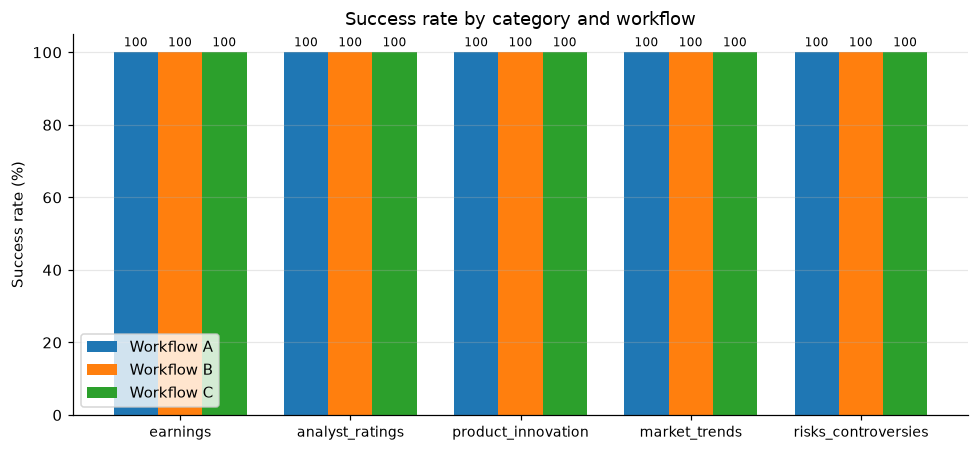

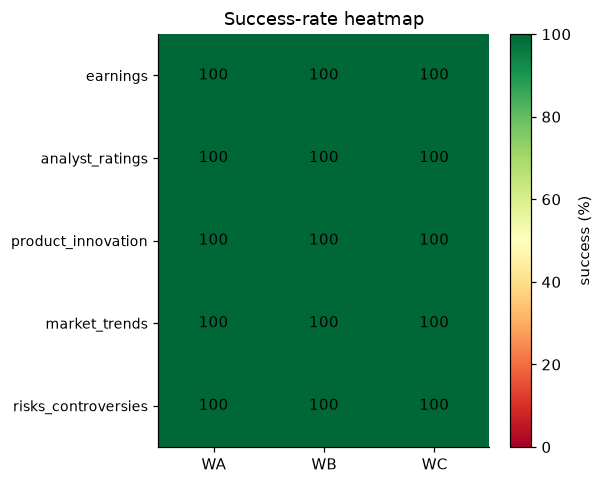

In [7]:
succ_cat = (df.assign(s=df["success"].astype(bool))
              .pivot_table(index="category", columns="workflow", values="s",
                           aggfunc="mean")
              .reindex(index=CATEGORIES, columns=WORKFLOWS) * 100)

display(succ_cat.round(1))

fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(CATEGORIES))
width = 0.26
for k, w in enumerate(WORKFLOWS):
    vals = succ_cat[w].values
    bars = ax.bar(x + (k - 1) * width, vals, width, label=f"Workflow {w}")
    ax.bar_label(bars, fmt="%.0f", fontsize=8, padding=2)

ax.set_xticks(x, CATEGORIES, fontsize=9)
ax.set_ylabel("Success rate (%)")
ax.set_title("Success rate by category and workflow")
ax.set_ylim(0, 105)
ax.legend()
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(PROJECT / "reports" / "eval_success_by_category.png", bbox_inches="tight")
plt.show()

# same view as a heatmap
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(succ_cat.values, cmap="RdYlGn", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(WORKFLOWS)), [f"W{w}" for w in WORKFLOWS])
ax.set_yticks(range(len(CATEGORIES)), CATEGORIES, fontsize=9)
for i in range(len(CATEGORIES)):
    for j in range(len(WORKFLOWS)):
        ax.text(j, i, f"{succ_cat.values[i, j]:.0f}", ha="center", va="center",
                color="black", fontsize=10)
fig.colorbar(im, label="success (%)")
ax.set_title("Success-rate heatmap")
fig.tight_layout()
fig.savefig(PROJECT / "reports" / "eval_success_heatmap.png", bbox_inches="tight")
plt.show()

### Per-stock drill-down

Mean TaskCompletion score and success rate for every category-stock cell, per workflow.
`best` names the workflow with the highest TaskCompletion score in that cell.

In [8]:
for col, base in [("TaskCompletion", "TaskCompletionMetric_score"), ("Success", None)]:
    if base is None:
        piv = (df.assign(s=df["success"].astype(bool))
                 .pivot_table(index=["stock", "category"], columns="workflow",
                              values="s", aggfunc="mean") * 100)
        unit = "%"
    else:
        piv = df.pivot_table(index=["stock", "category"], columns="workflow",
                             values=base, aggfunc="mean")
        unit = ""
    piv["best"] = piv[WORKFLOWS].idxmax(axis=1)
    piv.columns = [f"{c}{unit}" if c in WORKFLOWS else c for c in piv.columns]
    print(f"--- {col} ---")
    display(piv.round(1))
    print()

# summary: how many of the 25 category-stock cells each workflow wins (TaskCompletion)
tc = df.pivot_table(index=["stock", "category"], columns="workflow",
                    values="TaskCompletionMetric_score", aggfunc="mean")
print("Cells won (TaskCompletion, of 25):")
print(tc.idxmax(axis=1).value_counts())

--- TaskCompletion ---


A    B    C best
stock category                               
AAPL  analyst_ratings      0.4  0.1  0.3    A
      earnings             0.5  0.4  0.4    A
      market_trends        0.7  0.8  0.6    B
      product_innovation   0.5  0.6  0.5    B
      risks_controversies  0.6  0.6  0.5    A
AMZN  analyst_ratings      0.3  0.1  0.1    A
      earnings             0.2  0.3  0.3    B
      market_trends        0.6  0.5  0.4    A
      product_innovation   0.6  0.5  0.5    A
      risks_controversies  0.6  0.7  0.5    B
MSFT  analyst_ratings      0.3  0.2  0.2    A
      earnings             0.2  0.5  0.4    B
      market_trends        0.5  0.7  0.7    B
      product_innovation   0.4  0.5  0.4    B
      risks_controversies  0.4  0.5  0.5    B
NVDA  analyst_ratings      0.0  0.4  0.2    B
      earnings             0.3  0.4  0.5    C
      market_trends        0.4  0.6  0.6    B
      product_innovation   0.4  0.4  0.6    C
      risks_controversies  0.4  0.4  0.4    A
TSLA  analyst_ratings      0.2  0.1  0.1    A
      earnings             0.2  0.2  0.2    C
      market_trends        0.6  0.6  0.5    A
      product_innovation   0.5  0.3  0.5    A
      risks_controversies  0.5  0.3  0.5    A


--- Success ---


A%     B%     C% best
stock category                                     
AAPL  analyst_ratings      100.0  100.0  100.0    A
      earnings             100.0  100.0  100.0    A
      market_trends        100.0  100.0  100.0    A
      product_innovation   100.0  100.0  100.0    A
      risks_controversies  100.0  100.0  100.0    A
AMZN  analyst_ratings      100.0  100.0  100.0    A
      earnings             100.0  100.0  100.0    A
      market_trends        100.0  100.0  100.0    A
      product_innovation   100.0  100.0  100.0    A
      risks_controversies  100.0  100.0  100.0    A
MSFT  analyst_ratings      100.0  100.0  100.0    A
      earnings             100.0  100.0  100.0    A
      market_trends        100.0  100.0  100.0    A
      product_innovation   100.0  100.0  100.0    A
      risks_controversies  100.0  100.0  100.0    A
NVDA  analyst_ratings      100.0  100.0  100.0    A
      earnings             100.0  100.0  100.0    A
      market_trends        100.0  100.0  100.0    A
      product_innovation   100.0  100.0  100.0    A
      risks_controversies  100.0  100.0  100.0    A
TSLA  analyst_ratings      100.0  100.0  100.0    A
      earnings             100.0  100.0  100.0    A
      market_trends        100.0  100.0  100.0    A
      product_innovation   100.0  100.0  100.0    A
      risks_controversies  100.0  100.0  100.0    A


Cells won (TaskCompletion, of 25):
A    12
B    10
C     3
Name: count, dtype: int64


## 4. Summary: best workflow per category

Rule for "best": whichever workflow has the higher **TaskCompletion** mean score in
that category; the success rate is shown alongside as the binary check.

In [9]:
summary = pd.DataFrame({
    "best_tc_workflow": cat_table("TaskCompletionMetric")["best"],
    "success_A_%": succ_cat["A"],
    "success_B_%": succ_cat["B"],
    "success_C_%": succ_cat["C"],
})
display(summary.round(1))

print()
print("Overall best workflow (TaskCompletion):",
      overall["Task Completion"].idxmax())
print("Overall best workflow (Success rate):",
      overall["Success rate"].idxmax())

,best_tc_workflow,success_A_%,success_B_%,success_C_%
category,,,,
earnings,C,100.0,100.0,100.0
analyst_ratings,A,100.0,100.0,100.0
product_innovation,C,100.0,100.0,100.0
market_trends,B,100.0,100.0,100.0
risks_controversies,A,100.0,100.0,100.0



Overall best workflow (TaskCompletion): B
Overall best workflow (Success rate): A
